# AI 1 — Lab 2: Classification

**Names:** Avery John, Josh Samuel, Zachary Jennings

**Dataset:** UCI Secondary Mushroom Dataset (same as MiniLab)  

## 1. Business Understanding (CRISP-DM)****

We are using mushroom characteristics to study two classification questions:

1. **Task 1 — Edible or poisonous?** Predict whether a mushroom is poisonous from physical characteristics. In the model, `1 = poisonous` and `0 = edible`. A **false negative** here means a poisonous mushroom was classified as edible. This is the mistake we especially want to avoid, so poisonous recall is our primary measure. Precision still matters because classifying every mushroom as poisonous would have high recall but would not be very useful.
2. **Task 2 — Does the mushroom bruise or bleed?** Predict whether the mushroom bruises or bleeds using other characteristics. In the model, `1 = yes` and `0 = no`. This could be useful for estimating a trait when the mushroom has not been physically tested. Unlike the first task, neither type of error has a clearly established greater cost. We will use **F1** as a primary measure and also report accuracy, precision, and recall.

These are **educational predictive models**, not safe identification tools for deciding whether to eat wild mushrooms. A high score on this dataset alone does not establish real-world safety.

## 2. Data Understanding

### 2.1 Load Libraries

In [28]:
# Load libraries
import os
import time
from itertools import combinations

import certifi
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import binomtest
from ucimlrepo import fetch_ucirepo

from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     cross_val_score, GridSearchCV)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, recall_score, precision_score,
                             classification_report, f1_score, confusion_matrix,
                             ConfusionMatrixDisplay, RocCurveDisplay)

pd.set_option("display.max_columns", 50)
os.environ.setdefault("SSL_CERT_FILE", certifi.where())
RANDOM_STATE = 42


### 2.2 Cleaning the Mushroom Data

In MiniLab, we cleaned our dataset from external file `clean.py`. The following code is copied from that, which renames the categorical variables, fills in missing values, and engineers two new features.

In [29]:
# clean.py
import os
import certifi
os.environ.setdefault("SSL_CERT_FILE", certifi.where())

import pandas as pd
from ucimlrepo import fetch_ucirepo

decode_map = {
    'class': {'p': 'poisonous', 'e': 'edible'},
    'cap-shape': {'b': 'bell', 'c': 'conical', 'x': 'convex', 'f': 'flat',
                  's': 'sunken', 'p': 'spherical', 'o': 'others'},
    'cap-surface': {'i': 'fibrous', 'g': 'grooves', 'y': 'scaly', 's': 'smooth',
                    'h': 'shiny', 'l': 'leathery', 'k': 'silky', 't': 'sticky',
                    'w': 'wrinkled', 'e': 'fleshy'},
    'cap-color': {'n': 'brown', 'b': 'buff', 'g': 'gray', 'r': 'green', 'p': 'pink',
                  'u': 'purple', 'e': 'red', 'w': 'white', 'y': 'yellow',
                  'l': 'blue', 'o': 'orange', 'k': 'black'},
    'does-bruise-or-bleed': {'t': 'yes', 'f': 'no'},
    'gill-attachment': {'a': 'adnate', 'x': 'adnexed', 'd': 'decurrent', 'e': 'free',
                        's': 'sinuate', 'p': 'pores', 'f': 'none', '?': 'unknown'},
    'gill-spacing': {'c': 'close', 'd': 'distant', 'f': 'none'},
    'gill-color': {'n': 'brown', 'b': 'buff', 'g': 'gray', 'r': 'green', 'p': 'pink',
                   'u': 'purple', 'e': 'red', 'w': 'white', 'y': 'yellow',
                   'l': 'blue', 'o': 'orange', 'k': 'black', 'f': 'none'},
    'stem-root': {'b': 'bulbous', 's': 'swollen', 'c': 'club', 'u': 'cup',
                  'e': 'equal', 'z': 'rhizomorphs', 'r': 'rooted', 'f': 'fibrous'},
    'stem-surface': {'i': 'fibrous', 'g': 'grooves', 'y': 'scaly', 's': 'smooth',
                     'h': 'shiny', 'l': 'leathery', 'k': 'silky', 't': 'sticky',
                     'w': 'wrinkled', 'e': 'fleshy', 'f': 'none'},
    'stem-color': {'n': 'brown', 'b': 'buff', 'g': 'gray', 'r': 'green', 'p': 'pink',
                   'u': 'purple', 'e': 'red', 'w': 'white', 'y': 'yellow',
                   'l': 'blue', 'o': 'orange', 'k': 'black', 'f': 'none'},
    'veil-type': {'p': 'partial', 'u': 'universal'},
    'veil-color': {'n': 'brown', 'b': 'buff', 'g': 'gray', 'r': 'green', 'p': 'pink',
                   'u': 'purple', 'e': 'red', 'w': 'white', 'y': 'yellow',
                   'l': 'blue', 'o': 'orange', 'k': 'black', 'f': 'none'},
    'has-ring': {'t': 'ring', 'f': 'none'},
    'ring-type': {'c': 'cobwebby', 'e': 'evanescent', 'r': 'flaring', 'g': 'grooved',
                  'l': 'large', 'p': 'pendant', 's': 'sheathing', 'z': 'zone',
                  'y': 'scaly', 'm': 'movable', 'f': 'none', '?': 'unknown'},
    'spore-print-color': {'n': 'brown', 'b': 'buff', 'g': 'gray', 'r': 'green', 'p': 'pink',
                          'u': 'purple', 'e': 'red', 'w': 'white', 'y': 'yellow',
                          'l': 'blue', 'o': 'orange', 'k': 'black'},
    'season': {'s': 'spring', 'u': 'summer', 'a': 'autumn', 'w': 'winter'},
    'habitat': {'g': 'grasses', 'l': 'leaves', 'm': 'meadows', 'p': 'paths',
                'h': 'heaths', 'u': 'urban', 'w': 'waste', 'd': 'woods'}
}


def load_raw() -> pd.DataFrame:
    secondary_mushroom = fetch_ucirepo(id=848)
    X = secondary_mushroom.data.features
    y = secondary_mushroom.data.targets
    return pd.concat([X, y], axis=1)


def clean_mushrooms(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()

    # Decode letter codes to words
    for col, mapping in decode_map.items():
        df[col] = df[col].map(mapping)

    # Drop exact duplicates (146 rows, -> 60,923)
    df = df.drop_duplicates().reset_index(drop=True)

    # Fill missing categoricals with an explicit "Missing" category
    cat_cols = df.select_dtypes(include="object").columns
    df[cat_cols] = df[cat_cols].fillna("Missing")

    # Engineered features
    df["has-stem"] = ~((df["stem-height"] == 0) & (df["stem-width"] == 0))
    df["has-stem"] = df["has-stem"].map({True: "yes", False: "no"})
    df["size-score"] = df["cap-diameter"] + df["stem-height"] + df["stem-width"] / 10

    return df


In [30]:
# Load clean dataset
df = clean_mushrooms(load_raw())
print("Dataset dimensions:", df.shape)
print("Column types:\n", df.dtypes.value_counts())
print("Remaining NA values:\n", df.isna().sum())


Dataset dimensions: (60923, 23)
Column types:
 str        19
float64     4
Name: count, dtype: int64
Remaining NA values:
 cap-diameter            0
cap-shape               0
cap-surface             0
cap-color               0
does-bruise-or-bleed    0
gill-attachment         0
gill-spacing            0
gill-color              0
stem-height             0
stem-width              0
stem-root               0
stem-surface            0
stem-color              0
veil-type               0
veil-color              0
has-ring                0
ring-type               0
spore-print-color       0
habitat                 0
season                  0
class                   0
has-stem                0
size-score              0
dtype: int64


/var/folders/qy/yl4hyv4s5kz52wg1qlh36y_w0000gn/T/ipykernel_59111/1312590240.py:69: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include="object").columns


### 2.3 Explore the Two Target Variables

Before modeling, we need to check how often each class occurs. The plots below give context for choosing our evaluation metrics.

Task 1: Class distribution
class
poisonous    33742
edible       27181
Name: count, dtype: int64

Task 1 proportions
class
poisonous    0.554
edible       0.446
Name: proportion, dtype: float64

Task 2: Bruise/bleed distribution
does-bruise-or-bleed
no     50333
yes    10590
Name: count, dtype: int64

Task 2 proportions
does-bruise-or-bleed
no     0.826
yes    0.174
Name: proportion, dtype: float64


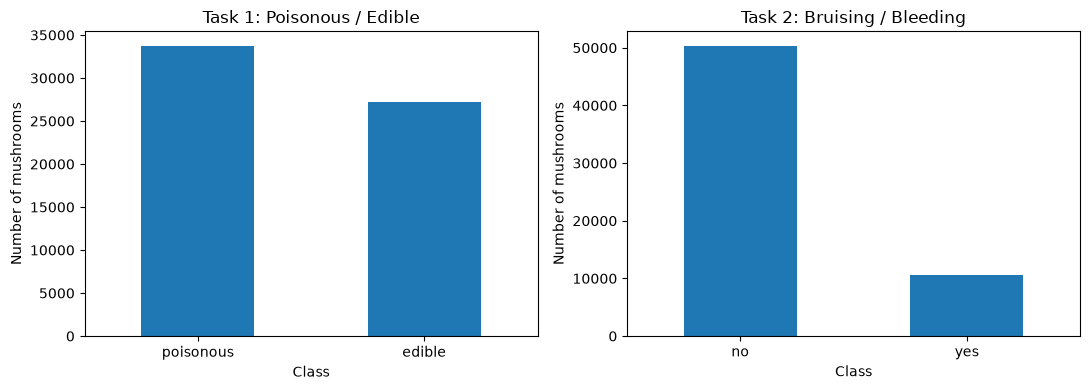

In [4]:
print("Task 1: Class distribution")
print(df["class"].value_counts(dropna=False))
print("\nTask 1 proportions")
print(df["class"].value_counts(normalize=True, dropna=False).round(3))

print("\nTask 2: Bruise/bleed distribution")
print(df["does-bruise-or-bleed"].value_counts(dropna=False))
print("\nTask 2 proportions")
print(df["does-bruise-or-bleed"].value_counts(normalize=True, dropna=False).round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
df["class"].value_counts().plot(kind="bar", ax=axes[0], title="Task 1: Poisonous / Edible")
df["does-bruise-or-bleed"].value_counts().plot(kind="bar", ax=axes[1], title="Task 2: Bruising / Bleeding")
axes[0].set_ylabel("Number of mushrooms")
axes[1].set_ylabel("Number of mushrooms")
for ax in axes:
    ax.set_xlabel("Class")
    ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()


## 3. Data Preparation

### 3.1 Define the Two Classification Tasks

**Task 1:** `class` is the target. We exclude it from the predictors.

**Task 2:** `does-bruise-or-bleed` is the target. We exclude both the target itself **and** `class` from the predictors. A real user applying the second model would not necessarily already know whether their mushroom was edible or poisonous, so using that label could make the second task unrealistic.

In [34]:
# Task 1: edible (0) versus poisonous (1)
class_df = df[df["class"].isin(["edible", "poisonous"])].copy()
X1 = class_df.drop(columns="class")
y1 = (class_df["class"] == "poisonous").astype(int)

# Task 2: no bruising (0) versus yes bruising (1)
bruise_df = df[df["does-bruise-or-bleed"].isin(["yes", "no"])].copy()
X2 = bruise_df.drop(columns=["class", "does-bruise-or-bleed"])
y2 = (bruise_df["does-bruise-or-bleed"] == "yes").astype(int)

print("Task 1 X/y shapes:", X1.shape, y1.shape)
print("Task 1 values:", y1.value_counts().to_dict())
print("Task 2 X/y shapes:", X2.shape, y2.shape)
print("Task 2 values:", y2.value_counts().to_dict())
print("Rows excluded from Task 1:", len(df) - len(class_df))
print("Rows excluded from Task 2:", len(df) - len(bruise_df))


Task 1 X/y shapes: (60923, 22) (60923,)
Task 1 values: {1: 33742, 0: 27181}
Task 2 X/y shapes: (60923, 21) (60923,)
Task 2 values: {0: 50333, 1: 10590}
Rows excluded from Task 1: 0
Rows excluded from Task 2: 0


### 3.2 Divide the Data — Holdout + Stratified 5-Fold CV

We use a **stratified 80/20 training/testing split**, the same split size as in the MiniLab. The 20% test set is large enough to evaluate errors on unseen examples while leaving most observations available for training. Given the imbalanced target class for task 2, we use stratification to help keep class proportions approximately the same in each subset.

For training and parameter selection, we use **stratified 5-fold cross-validation** on only the 80% training portion. With a large dataset, 5 folds are a reasonable balance between stability and computing time. Preprocessing is learned inside each fold via our pipelines; the separate 20% test set is not used for selecting hyperparameters.

In [7]:
# Task 1 split
X1_train, X1_test, y1_train, y1_test = train_test_split(
    X1, y1, test_size=0.20, random_state=RANDOM_STATE, stratify=y1
)

# Task 2 split
X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y2, test_size=0.20, random_state=RANDOM_STATE, stratify=y2
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

print("Task 1 train/test:", X1_train.shape, X1_test.shape)
print("Task 2 train/test:", X2_train.shape, X2_test.shape)
print("Task 1 positive fraction in train/test:", y1_train.mean().round(3), y1_test.mean().round(3))
print("Task 2 positive fraction in train/test:", y2_train.mean().round(3), y2_test.mean().round(3))


Task 1 train/test: (48738, 22) (12185, 22)
Task 2 train/test: (48738, 21) (12185, 21)
Task 1 positive fraction in train/test: 0.554 0.554
Task 2 positive fraction in train/test: 0.174 0.174


### 3.3 Preprocessing Pipelines

Like the MiniLab, we use a `ColumnTransformer` with `StandardScaler` on numerical columns and `OneHotEncoder(handle_unknown="ignore")` on categorical columns. Separate preprocessors are created for the two tasks because the predictor columns differ.

We use the **same preprocessing structure for each algorithm** within a task for consistency. 

Trees do not require standardized variables, but it does not prevent the comparison. Additionally, standardized variables gives us the flexibility to utilize other models that do require standardization without having to recreate the `Pipeline`.

In [ ]:
# Task 1 preprocessing
num_cols1 = X1_train.select_dtypes("number").columns
cat_cols1 = X1_train.select_dtypes(exclude="number").columns
preprocess1 = ColumnTransformer([
    ("num", StandardScaler(), num_cols1),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols1)
])

# Task 2 preprocessing
num_cols2 = X2_train.select_dtypes("number").columns
cat_cols2 = X2_train.select_dtypes(exclude="number").columns
preprocess2 = ColumnTransformer([
    ("num", StandardScaler(), num_cols2),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols2)
])

print("Task 1 numeric features:", list(num_cols1))
print("Task 1 categorical features:", list(cat_cols1))
print("Task 2 numeric features:", list(num_cols2))
print("Task 2 categorical features:", list(cat_cols2))


Task 1 numeric features: ['cap-diameter', 'stem-height', 'stem-width', 'size-score']
Task 1 categorical features: ['cap-shape', 'cap-surface', 'cap-color', 'does-bruise-or-bleed', 'gill-attachment', 'gill-spacing', 'gill-color', 'stem-root', 'stem-surface', 'stem-color', 'veil-type', 'veil-color', 'has-ring', 'ring-type', 'spore-print-color', 'habitat', 'season', 'has-stem']
Task 2 numeric features: ['cap-diameter', 'stem-height', 'stem-width', 'size-score']
Task 2 categorical features: ['cap-shape', 'cap-surface', 'cap-color', 'gill-attachment', 'gill-spacing', 'gill-color', 'stem-root', 'stem-surface', 'stem-color', 'veil-type', 'veil-color', 'has-ring', 'ring-type', 'spore-print-color', 'habitat', 'season', 'has-stem']


## 4. Modeling — Task 1: Poisonous vs. Edible

### 4.1 Our Three Models

1. **Logistic Regression:**
2. **Decision Tree:**
3. **Random Forest:** 

We do not need PCA here because we have a manageable number of source predictors and one-hot encoded categories. The decision to avoid PCA also preserves direct feature interpretation.

**Primary tuning metric: poisonous recall** (`scoring="recall"`). This measures the fraction of actual poisonous mushrooms we catch. We also report precision and F1 to ensure recall is not achieved merely by flagging everything as poisonous.

In [9]:
# Task 1: Three baseline pipelines
log_reg1 = Pipeline([
    ("prep", preprocess1),
    ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
])

tree1 = Pipeline([
    ("prep", preprocess1),
    ("model", DecisionTreeClassifier(random_state=RANDOM_STATE))
])

forest1 = Pipeline([
    ("prep", preprocess1),
    ("model", RandomForestClassifier(n_estimators=80, random_state=RANDOM_STATE,
                                      n_jobs=1))
])

models1 = {"Logistic Regression": log_reg1,
           "Decision Tree": tree1,
           "Random Forest": forest1}


### 4.2 Baseline Performance with Cross-Validation

In [36]:
# Baseline CV recall (training portion only)
rows1 = []
for name, model in models1.items():
    start_time = time.perf_counter()
    scores = cross_val_score(model, X1_train, y1_train, cv=cv,
                             scoring="recall", n_jobs=-1)
    elapsed_time = time.perf_counter() - start_time
    rows1.append({"Model": name, "Mean CV Recall": scores.mean(),
                   "Fold Scores": np.round(scores, 4), "Baseline CV Time (seconds)": elapsed_time})

baseline1 = pd.DataFrame(rows1)
print(baseline1.to_string(index=False))


              Model  Mean CV Recall                              Fold Scores  Baseline CV Time (seconds)
Logistic Regression        0.872967 [0.8765, 0.8757, 0.8678, 0.8738, 0.8711]                    2.372989
      Decision Tree        0.998444 [0.9983, 0.9981, 0.9987, 0.9987, 0.9983]                    1.900086
      Random Forest        0.999926          [1.0, 0.9998, 1.0, 0.9998, 1.0]                    4.910042


### 4.3 Tune the Three Models

Just like the MiniLab, we use `GridSearchCV` and `model__` to tune hyperparameters inside each pipeline. We keep grids fairly small because random forests are more computationally expensive than logistic regression.

- **Logistic Regression:** `C` controls regularization; `class_weight` changes how the classes are weighted.
- **Decision Tree:** `max_depth` limits tree complexity; `min_samples_leaf` prevents tiny terminal leaves.
- **Random Forest:** `max_depth` and `min_samples_leaf` help control complexity. We hold `n_estimators=80` fixed here for a manageable runtime.

In [ ]:
# Task 1 hyperparameter grids
lr_grid1 = {
    "model__C": [0.1, 1, 10],
    "model__class_weight": [None, "balanced"]
}
tree_grid1 = {
    "model__max_depth": [10, 20, None],
    "model__min_samples_leaf": [1, 5]
}
forest_grid1 = {
    "model__max_depth": [15, None],
    "model__min_samples_leaf": [1, 4]
}

grids1 = {"Logistic Regression": lr_grid1,
          "Decision Tree": tree_grid1,
          "Random Forest": forest_grid1}

searches1 = {}
best_models1 = {}
times1 = {}

for name, model in models1.items():
    search = GridSearchCV(model, grids1[name], cv=cv,
                          scoring="recall", n_jobs=-1)
    start_time = time.time()
    search.fit(X1_train, y1_train)
    times1[name] = time.time() - start_time
    searches1[name] = search
    best_models1[name] = search.best_estimator_


In [38]:
# Task 1 CV tuning comparison
tuned_cv1 = pd.DataFrame([
    {"Model": name,
     "Best CV Recall": search.best_score_,
     "Tuning Time (seconds)": times1[name],
     "Best Params": str(search.best_params_)}
    for name, search in searches1.items()
])
print(tuned_cv1.to_string(index=False))


              Model  Best CV Recall  Tuning Time (seconds)                                              Best Params
Logistic Regression        0.873967               5.381598            {'model__C': 10, 'model__class_weight': None}
      Decision Tree        0.998444               3.318703 {'model__max_depth': None, 'model__min_samples_leaf': 1}
      Random Forest        0.999926              14.563584 {'model__max_depth': None, 'model__min_samples_leaf': 1}


## 5. Modeling — Task 2: Predict Bruising / Bleeding

For Task 2, we use **F1** as our evaluation metric to balance the cost of false positives and false negatives for the `yes` class, since neither error has the same clear safety priority that Task 1 has.

In [41]:
# Task 2: Three baseline pipelines
log_reg2 = Pipeline([
    ("prep", preprocess2),
    ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
])

tree2 = Pipeline([
    ("prep", preprocess2),
    ("model", DecisionTreeClassifier(random_state=RANDOM_STATE))
])

forest2 = Pipeline([
    ("prep", preprocess2),
    ("model", RandomForestClassifier(n_estimators=80, random_state=RANDOM_STATE,
                                      n_jobs=1))
])

models2 = {"Logistic Regression": log_reg2,
           "Decision Tree": tree2,
           "Random Forest": forest2}


In [ ]:
# Baseline CV F1 for Task 2
rows2 = []
for name, model in models2.items():
    start_time = time.perf_counter()
    scores = cross_val_score(model, X2_train, y2_train, cv=cv,
                             scoring="f1", n_jobs=-1)
    elapsed_time = time.perf_counter() - start_time
    rows2.append({"Model": name, "Mean CV F1": scores.mean(),
                   "Fold Scores": np.round(scores, 4), "Baseline CV Time (seconds)": elapsed_time})

baseline2 = pd.DataFrame(rows2)
print(baseline2.to_string(index=False))


              Model  Mean CV F1                              Fold Scores  Baseline CV Time (seconds)
Logistic Regression    0.857051 [0.8559, 0.8592, 0.8557, 0.8557, 0.8588]                    1.021069
      Decision Tree    0.997285 [0.9965, 0.9968, 0.9976, 0.9991, 0.9965]                    0.695157
      Random Forest    0.999823       [0.9997, 0.9997, 1.0, 1.0, 0.9997]                    2.822805


### 5.1 Tune Task 2 Models

We search the same types of hyperparameters as Task 1, but the models are refit independently. Here the CV scoring metric is `f1` instead of `recall`. Using the same candidate grids makes it easier to discuss why different settings may work best for different targets.

In [47]:
# Task 2 hyperparameter grids
lr_grid2 = {
    "model__C": [0.1, 1, 10],
    "model__class_weight": [None, "balanced"]
}
tree_grid2 = {
    "model__max_depth": [10, 20, None],
    "model__min_samples_leaf": [1, 5]
}
forest_grid2 = {
    "model__max_depth": [15, None],
    "model__min_samples_leaf": [1, 4]
}

grids2 = {"Logistic Regression": lr_grid2,
          "Decision Tree": tree_grid2,
          "Random Forest": forest_grid2}

searches2 = {}
best_models2 = {}
times2 = {}

for name, model in models2.items():
    search = GridSearchCV(model, grids2[name], cv=cv,
                          scoring="f1", n_jobs=-1)
    start_time = time.time()
    search.fit(X2_train, y2_train)
    times2[name] = time.time() - start_time
    searches2[name] = search
    best_models2[name] = search.best_estimator_


In [48]:
# Task 2 CV tuning comparison
tuned_cv2 = pd.DataFrame([
    {"Model": name,
     "Best CV F1": search.best_score_,
     "Tuning Time (seconds)": times2[name],
     "Best Params": str(search.best_params_)}
    for name, search in searches2.items()
])
print(tuned_cv2.to_string(index=False))


              Model  Best CV F1  Tuning Time (seconds)                                              Best Params
Logistic Regression    0.866312               4.305213            {'model__C': 10, 'model__class_weight': None}
      Decision Tree    0.997285               2.795005 {'model__max_depth': None, 'model__min_samples_leaf': 1}
      Random Forest    0.999823              11.796917 {'model__max_depth': None, 'model__min_samples_leaf': 1}


## 6. Evaluation (Both Tasks)

### 6.1 Final Evaluation on the Held-Out Test Data

Only **after choosing model settings via CV**, we evaluate all six tuned models on the independent 20% test sets. For both tasks, we show accuracy, positive-class precision, positive-class recall, F1, and confusion-matrix error counts. For Task 1 the positive class is **poisonous**. For Task 2 it is **yes (bruises/bleeds)**.

In [49]:
# Test predictions and evaluation results
predictions1 = {}
predictions2 = {}
rows = []

for name, model in best_models1.items():
    p = model.predict(X1_test)
    predictions1[name] = p
    tn, fp, fn, tp = confusion_matrix(y1_test, p, labels=[0, 1]).ravel()
    rows.append({"Task": "1: Poisonous", "Model": name,
                 "Accuracy": accuracy_score(y1_test, p),
                 "Precision": precision_score(y1_test, p, zero_division=0),
                 "Recall": recall_score(y1_test, p, zero_division=0),
                 "F1": f1_score(y1_test, p, zero_division=0),
                 "False Positives": fp, "False Negatives": fn,
                 "CV Best Score": searches1[name].best_score_,
                 "Tuning Time (s)": times1[name]})

for name, model in best_models2.items():
    p = model.predict(X2_test)
    predictions2[name] = p
    tn, fp, fn, tp = confusion_matrix(y2_test, p, labels=[0, 1]).ravel()
    rows.append({"Task": "2: Bruising", "Model": name,
                 "Accuracy": accuracy_score(y2_test, p),
                 "Precision": precision_score(y2_test, p, zero_division=0),
                 "Recall": recall_score(y2_test, p, zero_division=0),
                 "F1": f1_score(y2_test, p, zero_division=0),
                 "False Positives": fp, "False Negatives": fn,
                 "CV Best Score": searches2[name].best_score_,
                 "Tuning Time (s)": times2[name]})

comparison_table = pd.DataFrame(rows)
print(comparison_table.round(4).to_string(index=False))


        Task               Model  Accuracy  Precision  Recall     F1  False Positives  False Negatives  CV Best Score  Tuning Time (s)
1: Poisonous Logistic Regression    0.8646     0.8754  0.8809 0.8781              846              804         0.8740           5.3816
1: Poisonous       Decision Tree    0.9995     0.9996  0.9996 0.9996                3                3         0.9984           3.3187
1: Poisonous       Random Forest    0.9999     0.9999  1.0000 0.9999                1                0         0.9999          14.5636
 2: Bruising Logistic Regression    0.9584     0.8986  0.8574 0.8775              205              302         0.8663           4.3052
 2: Bruising       Decision Tree    0.9991     0.9972  0.9976 0.9974                6                5         0.9973           2.7950
 2: Bruising       Random Forest    1.0000     1.0000  1.0000 1.0000                0                0         0.9998          11.7969


In [50]:
# Print a full classification report
for name, p in predictions1.items():
    print("\nTask 1:", name)
    print(classification_report(y1_test, p, target_names=["edible", "poisonous"],
                                zero_division=0))

for name, p in predictions2.items():
    print("\nTask 2:", name)
    print(classification_report(y2_test, p, target_names=["no", "yes"],
                                zero_division=0))



Task 1: Logistic Regression
              precision    recall  f1-score   support

      edible       0.85      0.84      0.85      5436
   poisonous       0.88      0.88      0.88      6749

    accuracy                           0.86     12185
   macro avg       0.86      0.86      0.86     12185
weighted avg       0.86      0.86      0.86     12185


Task 1: Decision Tree
              precision    recall  f1-score   support

      edible       1.00      1.00      1.00      5436
   poisonous       1.00      1.00      1.00      6749

    accuracy                           1.00     12185
   macro avg       1.00      1.00      1.00     12185
weighted avg       1.00      1.00      1.00     12185


Task 1: Random Forest
              precision    recall  f1-score   support

      edible       1.00      1.00      1.00      5436
   poisonous       1.00      1.00      1.00      6749

    accuracy                           1.00     12185
   macro avg       1.00      1.00      1.00     12185

### 6.2 Comparing Accuracy, Recall, and F1

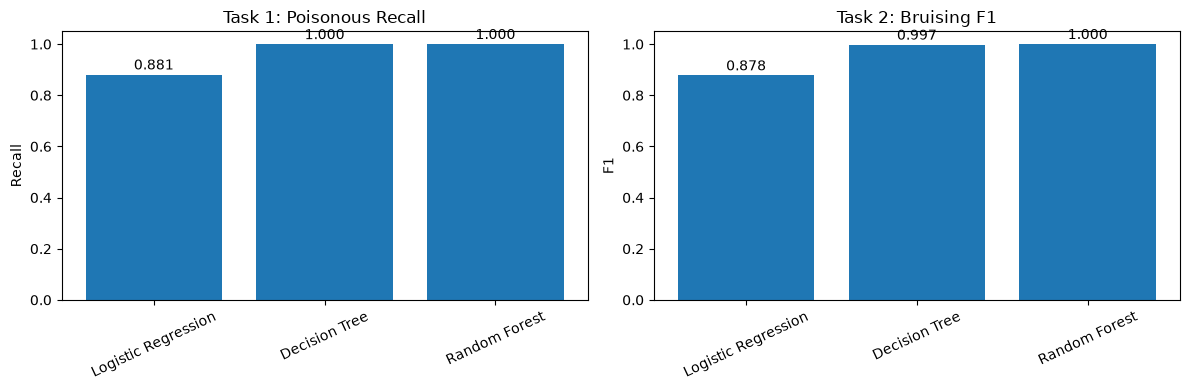

In [19]:
# Compare the models on the held-out test sets
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, task, metric, title in [
    (axes[0], "1: Poisonous", "Recall", "Task 1: Poisonous Recall"),
    (axes[1], "2: Bruising", "F1", "Task 2: Bruising F1")
]:
    sub = comparison_table[comparison_table["Task"] == task]
    ax.bar(sub["Model"], sub[metric])
    ax.set_ylim(0, 1.05)
    ax.set_ylabel(metric)
    ax.set_title(title)
    ax.tick_params(axis="x", rotation=25)
    for i, value in enumerate(sub[metric]):
        ax.text(i, min(value + 0.02, 1.02), f"{value:.3f}", ha="center")
plt.tight_layout()
plt.show()


### 6.3 Confusion Matrices

The confusion matrix summarizes four outcomes. For Task 1, the cell `actual poisonous / predicted edible` is the dangerous **false-negative** error. For Task 2, given our imbalanced target class (with `yes` being the smaller proportion), we would want to make sure that `actual yes / predicted no` is minimized as much as possible. These plots help us understand *which* mistakes a model makes instead of relying on accuracy alone.

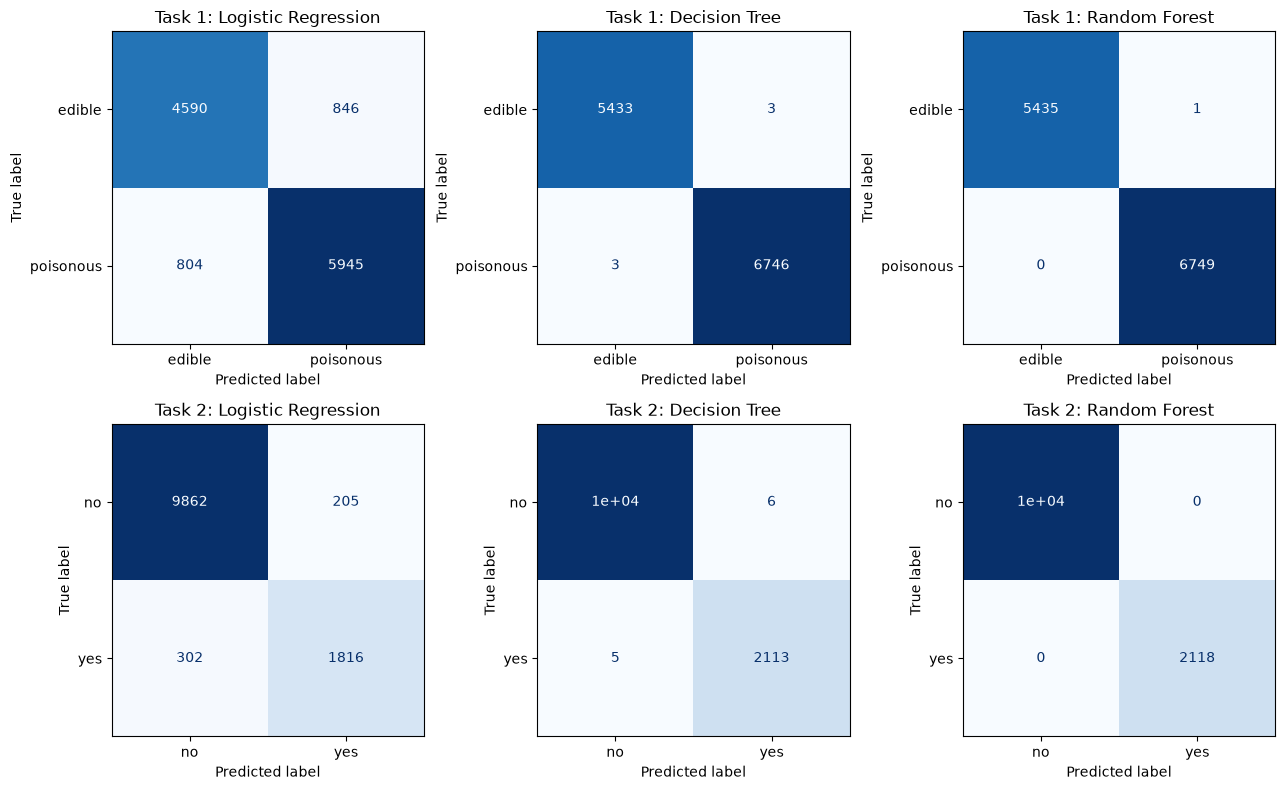

In [20]:
# Confusion matrices for all six tuned models
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for j, (name, p) in enumerate(predictions1.items()):
    ConfusionMatrixDisplay.from_predictions(
        y1_test, p, labels=[0, 1], display_labels=["edible", "poisonous"],
        cmap="Blues", colorbar=False, ax=axes[0, j]
    )
    axes[0, j].set_title("Task 1: " + name)

for j, (name, p) in enumerate(predictions2.items()):
    ConfusionMatrixDisplay.from_predictions(
        y2_test, p, labels=[0, 1], display_labels=["no", "yes"],
        cmap="Blues", colorbar=False, ax=axes[1, j]
    )
    axes[1, j].set_title("Task 2: " + name)
plt.tight_layout()
plt.show()


### 6.4 ROC Curves (from the Classification Lecture)

An ROC curve compares true-positive rate (recall) to false-positive rate over a range of decision thresholds. The closer the curve is to the upper-left corner, the better the ranking discrimination on these test examples. This is a **supplemental** view; a high ROC-AUC alone does not mean poisonous mushrooms will never be missed at the actual decision threshold.

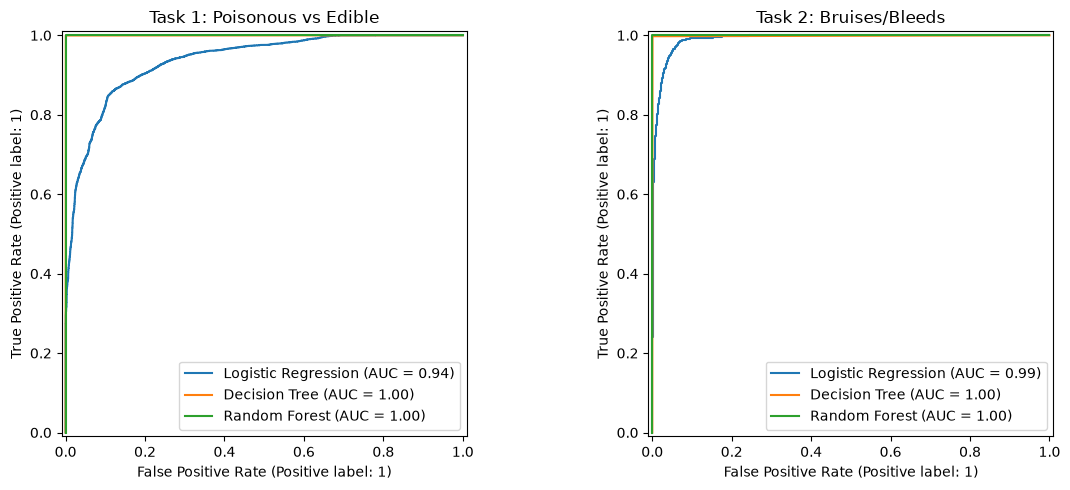

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for name, model in best_models1.items():
    RocCurveDisplay.from_estimator(model, X1_test, y1_test, name=name, ax=axes[0])
axes[0].set_title("Task 1: Poisonous vs Edible")

for name, model in best_models2.items():
    RocCurveDisplay.from_estimator(model, X2_test, y2_test, name=name, ax=axes[1])
axes[1].set_title("Task 2: Bruises/Bleeds")
plt.tight_layout()
plt.show()


### 6.5 Advantages of Each Model

### 6.5 Statistical Comparison — Are Differences Significant at 95% Confidence?

Our three models make predictions on the **same held-out examples**, so their errors are paired. We use the **exact McNemar/binomial test** to compare each model pair's *correct versus incorrect* predictions:

- Count `b`: examples where Model A was correct but Model B was wrong.
- Count `c`: examples where Model A was wrong but Model B was correct.
- Under the null hypothesis, the models are equally likely to be the one that gets a discordant example correct. If the exact two-sided p-value is small, the evidence indicates different error rates.

We have **three pairwise comparisons per task**, so we use a simple **Bonferroni correction**: compare adjusted p-values against 0.05 (equivalently, raw p-values against 0.05/3). This controls the chance of any false positive conclusion across the three comparisons within a task. **McNemar's test compares paired accuracy/error rates; it does not by itself compare F1.**

For Task 1, we also repeat the test only on the **actually poisonous** test examples. On that subset, being correct means detecting a poisonous mushroom, so the result tests differences in poisonous **recall**. Even then, lack of significance does not prove the models are equal.

In [22]:
# Statistical comparison using the same test observations for every model pair
# Exact McNemar p-value via a two-sided binomial test on discordant outcomes.
def mcnemar_comparisons(y_true, predictions):
    y_arr = np.asarray(y_true)
    results = []
    for a, b in combinations(predictions.keys(), 2):
        a_correct = (np.asarray(predictions[a]) == y_arr)
        b_correct = (np.asarray(predictions[b]) == y_arr)
        a_only = np.sum(a_correct & ~b_correct)
        b_only = np.sum(~a_correct & b_correct)
        disagreements = a_only + b_only
        p_value = (binomtest(int(a_only), int(disagreements), p=0.5).pvalue
                   if disagreements > 0 else 1.0)
        results.append({"Model A": a, "Model B": b,
                        "A correct / B wrong": int(a_only),
                        "A wrong / B correct": int(b_only),
                        "p-value": p_value})
    result = pd.DataFrame(results)
    result["Bonferroni-adjusted p"] = (result["p-value"] * len(result)).clip(upper=1)
    result["Significant at 95%"] = result["Bonferroni-adjusted p"] < 0.05
    return result

print("Task 1 — Paired accuracy/error-rate comparisons")
stat1 = mcnemar_comparisons(y1_test, predictions1)
print(stat1.to_string(index=False))

print("\nTask 2 — Paired accuracy/error-rate comparisons")
stat2 = mcnemar_comparisons(y2_test, predictions2)
print(stat2.to_string(index=False))


Task 1 — Paired accuracy/error-rate comparisons
            Model A       Model B  A correct / B wrong  A wrong / B correct  p-value  Bonferroni-adjusted p  Significant at 95%
Logistic Regression Decision Tree                    3                 1647    0.000                  0.000                True
Logistic Regression Random Forest                    1                 1650    0.000                  0.000                True
      Decision Tree Random Forest                    1                    6    0.125                  0.375               False

Task 2 — Paired accuracy/error-rate comparisons
            Model A       Model B  A correct / B wrong  A wrong / B correct       p-value  Bonferroni-adjusted p  Significant at 95%
Logistic Regression Decision Tree                    7                  503 1.033702e-138          3.101107e-138                True
Logistic Regression Random Forest                    0                  507 4.773338e-153          1.432001e-152             

In [23]:
# Task 1 only: paired recall comparison on actual poisonous examples
poisonous_mask = np.asarray(y1_test) == 1
poisonous_true = np.asarray(y1_test)[poisonous_mask]
poisonous_preds = {name: np.asarray(p)[poisonous_mask]
                   for name, p in predictions1.items()}

stat1_recall = mcnemar_comparisons(poisonous_true, poisonous_preds)
print("Task 1 — Comparisons of poisonous recall (positive cases only)")
print(stat1_recall.to_string(index=False))


Task 1 — Comparisons of poisonous recall (positive cases only)
            Model A       Model B  A correct / B wrong  A wrong / B correct       p-value  Bonferroni-adjusted p  Significant at 95%
Logistic Regression Decision Tree                    2                  803 3.040785e-237          9.122356e-237                True
Logistic Regression Random Forest                    0                  804 1.874621e-242          5.623863e-242                True
      Decision Tree Random Forest                    0                    3  2.500000e-01           7.500000e-01               False


**How to write up the statistical results:** Identify each comparison's *direction* using the test scores and discordance counts; a p-value alone does not tell you which model is better. If an adjusted p-value is below 0.05, report evidence for a difference at the 5% family-wise significance level. If it is not below 0.05, report **insufficient evidence of a difference**, not proof of equal performance.

For Task 2, the McNemar result compares error rates; it does **not** establish whether an observed difference in F1 is statistically significant. A paired bootstrap of F1 differences would be a possible extension if your professor wants formal F1 inference.

## 7. Feature Importance (Both Tasks)

Feature importance may tell us which mushroom attributes the models rely on most. We use two methods from the course materials:

- **Logistic Regression coefficients** (MiniLab Question 3). Positive coefficients increase the model's predicted log-odds of the `1` class; negative coefficients decrease it. One-hot variables compare one encoded category against the others represented in the model. Coefficients can be unstable when features are correlated.
- **Decision Tree and Random Forest `feature_importances_`** (professor's classification notebook). These describe how much splits using each encoded feature reduce node impurity. They do **not** prove a feature causes poisonousness or bruising, and impurity-based importance can favor some variable types.

Because categorical variables become multiple one-hot columns, an importance value for one encoded category is not necessarily the importance of the whole original attribute.

In [24]:
# Logistic Regression: top coefficients for both tasks
for task_name, fitted in [
    ("Task 1: Poisonous", best_models1["Logistic Regression"]),
    ("Task 2: Bruising", best_models2["Logistic Regression"])
]:
    features = fitted["prep"].get_feature_names_out()
    coefs = pd.Series(fitted["model"].coef_[0], index=features).sort_values()
    print("\n", task_name)
    print("Largest coefficients toward class 1:")
    print(coefs.tail(10).sort_values(ascending=False).round(3))
    print("Largest coefficients toward class 0:")
    print(coefs.head(10).round(3))



 Task 1: Poisonous
Largest coefficients toward class 1:
cat__ring-type_zone             12.220
cat__spore-print-color_black    10.912
cat__stem-root_club              9.980
cat__veil-type_universal         9.734
cat__veil-color_purple           9.397
cat__stem-surface_grooves        8.799
cat__stem-root_rooted            6.630
cat__stem-surface_shiny          6.511
cat__habitat_paths               5.881
cat__ring-type_evanescent        5.583
dtype: float64
Largest coefficients toward class 0:
cat__veil-color_yellow         -13.705
cat__ring-type_movable          -9.634
cat__veil-color_white           -8.786
cat__stem-color_blue            -6.779
cat__veil-type_Missing          -6.715
cat__stem-root_bulbous          -5.865
cat__stem-root_Missing          -5.617
cat__spore-print-color_gray     -5.284
cat__spore-print-color_white    -4.643
cat__stem-surface_sticky        -4.301
dtype: float64

 Task 2: Bruising
Largest coefficients toward class 1:
cat__veil-color_purple            15.099

In [25]:
# Decision Tree / Random Forest: importance of encoded features
for task_name, fitted_models in [
    ("Task 1: Poisonous", best_models1),
    ("Task 2: Bruising", best_models2)
]:
    for model_name in ["Decision Tree", "Random Forest"]:
        fitted = fitted_models[model_name]
        feature_names = fitted["prep"].get_feature_names_out()
        importances = pd.Series(fitted["model"].feature_importances_,
                                index=feature_names).sort_values(ascending=False)
        print("\n", task_name, "-", model_name)
        print(importances.head(12).round(4))



 Task 1: Poisonous - Decision Tree
num__stem-width                 0.1136
cat__gill-spacing_distant       0.0585
cat__stem-color_white           0.0312
num__size-score                 0.0309
cat__gill-attachment_adnexed    0.0288
cat__gill-color_pink            0.0285
cat__stem-surface_smooth        0.0273
cat__stem-surface_grooves       0.0242
num__stem-height                0.0236
cat__ring-type_zone             0.0235
cat__stem-surface_Missing       0.0235
cat__stem-root_rooted           0.0224
dtype: float64

 Task 1: Poisonous - Random Forest
num__stem-width               0.0752
num__size-score               0.0445
num__stem-height              0.0439
num__cap-diameter             0.0413
cat__stem-color_white         0.0339
cat__gill-spacing_distant     0.0257
cat__gill-attachment_pores    0.0199
cat__gill-color_white         0.0186
cat__stem-surface_Missing     0.0185
cat__gill-spacing_close       0.0182
cat__gill-spacing_Missing     0.0160
cat__cap-surface_Missing      0.0154
d

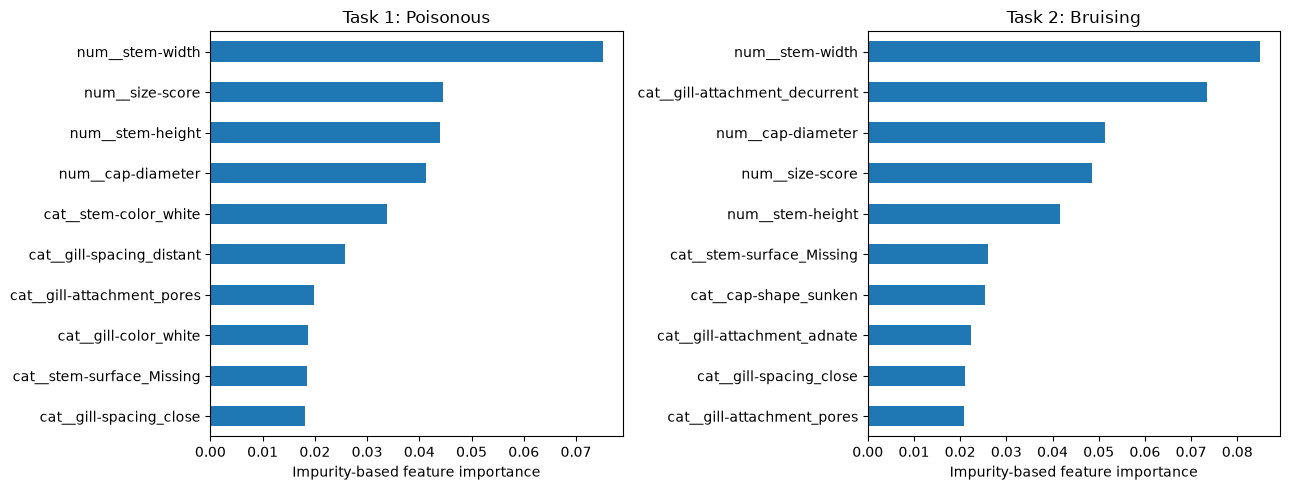

In [26]:
# Visualize top RF feature importances for both prediction tasks
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, title, fitted in [
    (axes[0], "Task 1: Poisonous", best_models1["Random Forest"]),
    (axes[1], "Task 2: Bruising", best_models2["Random Forest"])
]:
    names = fitted["prep"].get_feature_names_out()
    importance = pd.Series(fitted["model"].feature_importances_, index=names)
    importance.nlargest(10).sort_values().plot(kind="barh", ax=ax)
    ax.set_title(title)
    ax.set_xlabel("Impurity-based feature importance")
plt.tight_layout()
plt.show()


### 7.1 What Might Explain Important Variables?

Attributes such as surface, color, stem structure, or gill-related features may be predictive because they capture physical differences among mushroom types. The two engineered features (`has-stem` and `size-score`) may help the model combine simple measurements. However, we should check the **actual lists above** before naming the most important variables in our results. A feature that matters for predicting toxicity might not matter as much for predicting bruising.

**To complete with your actual outputs:** Name the top 3–5 attributes **for each task**, compare the logistic-regression and forest findings, and explain one plausible reason for any disagreement. Avoid interpreting these associations as biological causes.

## 8. Deployment (CRISP-DM)

A possible application would be an educational mushroom-data classification tool. A user would enter measurable features (such as cap appearance and stem measurements), and the model would return a predicted class along with a warning about limitations. The bruising model could estimate a physical trait that has not been tested directly. **Neither classifier should be used to decide whether a wild mushroom is safe to eat.**

To evaluate practical value, we would track the rates of incorrect predictions on **new, independently collected data**, with especially close attention to Task 1 false negatives. We would also monitor differences by region, mushroom type, and other populations once that information is available. If performance declines or the collected mushroom population changes, we would review preprocessing and retrain after collecting representative labeled examples. A reasonable operational process would schedule periodic reviews and also investigate any reported dangerous misclassification immediately.

Additional useful data could include confirmed species labels, geographic region, collection season and conditions, measurement quality, and expert-verified labels. Before any safety-sensitive use, the tool would require much stronger external validation, domain expertise, and protective procedures beyond what this student lab can provide.

## 9. Optional: Exceptional Work — Visualize Hyperparameter Performance

The rubric mentions parallel grid search and plots showing which settings improve performance. `GridSearchCV` already runs candidate settings across folds, and `n_jobs=-1` enables parallelism. As one extension, we can plot the **Decision Tree maximum depth versus cross-validation performance** for each task, averaged over the different values of `min_samples_leaf`. This may help explain why very deep trees do or do not generalize better.

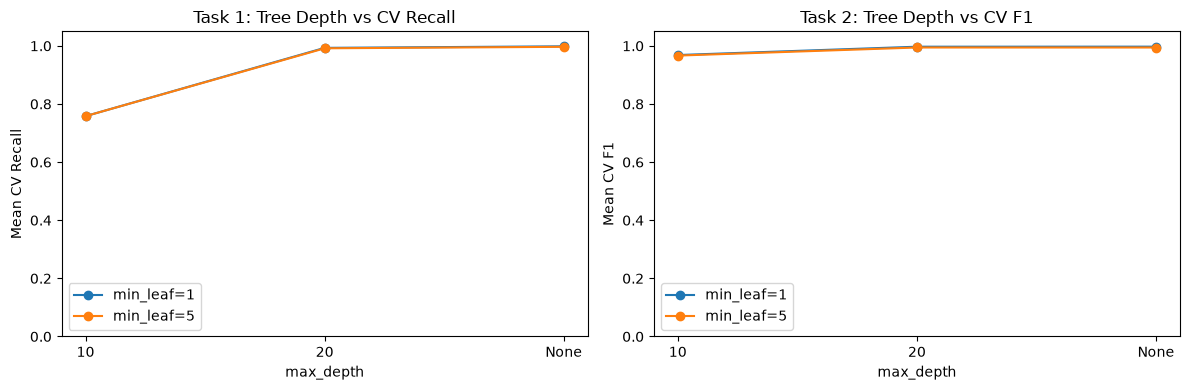

In [27]:
# Optional: visualize one parameter's effect using GridSearchCV results
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, search, title, metric in [
    (axes[0], searches1["Decision Tree"], "Task 1: Tree Depth vs CV Recall", "Recall"),
    (axes[1], searches2["Decision Tree"], "Task 2: Tree Depth vs CV F1", "F1")
]:
    tmp = pd.DataFrame(search.cv_results_)
    tmp["depth_label"] = tmp["param_model__max_depth"].map(lambda x: "None" if x is None else str(x))
    for leaf_size, grp in tmp.groupby("param_model__min_samples_leaf"):
        grouped = grp.groupby("depth_label")["mean_test_score"].mean()
        ax.plot(grouped.index, grouped.values, marker="o", label=f"min_leaf={leaf_size}")
    ax.set_title(title)
    ax.set_xlabel("max_depth")
    ax.set_ylabel("Mean CV " + metric)
    ax.set_ylim(0, 1.05)
    ax.legend()
plt.tight_layout()
plt.show()


## 10. Conclusions — Fill In After Running

We compared three model types on **two separate binary classification tasks**, using the same overall preparation and validation design. We tuned the models with stratified cross-validation on the training data and reserved the held-out test set for final evaluation. The experiments allow us to discuss the trade-off among prediction quality, interpretability, and computation time.

**Complete these conclusions from the notebook output before handing it in:**

1. **Task 1:** Which model had the highest *test poisonous recall*? How many poisonous mushrooms, if any, did it wrongly label edible? What was its precision and runtime? Was its performance significantly different from the other models?
2. **Task 2:** Which model had the best test *F1*? Did it outperform the others in both precision and recall, or was there a trade-off? What did the paired error-rate test show?
3. **Features:** Which actual attributes appeared important for each task? Were the top features consistent across logistic regression, decision tree, and random forest?
4. **Limitations:** Random held-out rows may be easier than identifying truly new mushroom populations. Perfect test scores, if observed, do not establish real-world safety.

**Do not include claims of 'best model,' 'statistically significant,' or specific numerical performance until you have executed and inspected the results.**

## Final Submission Checklist

- [ ] Add all group-member names.
- [ ] Run this notebook from the first cell to the last (fresh kernel, **Run All**).
- [ ] Verify both targets, class distributions, and how many rows were excluded.
- [ ] Confirm the three models for **each** task and review all best parameter settings.
- [ ] Interpret the primary metrics, confusion matrices, ROC curves, and model trade-offs.
- [ ] Report paired statistical comparisons carefully at 95% confidence.
- [ ] Add your group's observations about feature importance, including actual top attributes.
- [ ] Explain model value and practical limitations.
- [ ] Confirm all cells have outputs and all findings are supported by those outputs.
- [ ] Save the executed `.ipynb` as the final single-document report (or export to PDF/HTML).
- [ ] Follow your professor's rules on original student code and permitted AI/Codex use.

**Sources used to construct this worked draft:** Your supplied `MiniLab.ipynb`, `clean.py`, professor's `06. Classification.ipynb`, and the two-page Lab 2 instructions. The statistical-comparison lecture mentions `statcompare.py`, but that file was not included; the exact binomial/McNemar comparison here is an additional implementation, not copied from the professor's missing file.